# Plot binary MLP control classifier performance
Plots the per-patient DMSO-vs-Staurosporine MLP classifiers' training and held-out test-set performance, from the data saved by `1.train_binary_mlp_control.ipynb` and `2.evaluate_binary_mlp_control.ipynb`:

1. Per-patient training curves (train/val loss).
2. Precision-recall curves (per patient + pooled).

In [1]:
list_of_packages <- c("ggplot2", "dplyr", "tidyr", "arrow", "RColorBrewer")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(package, character.only = TRUE, quietly = TRUE, warn.conflicts = FALSE)
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

root_dir <- find_git_root()
source(file.path(root_dir, "utils", "r_plot_themes.r"))

module_dir <- file.path(root_dir, "6.treatment_predictive_model")
results_dir <- file.path(module_dir, "model_results")
figures_dir <- file.path(module_dir, "figures")
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)

PATIENT_COL <- "Metadata_Biology_PatientTumor"

TUMOR_TYPE_PALETTE <- tumor_type_palette
label_patient <- function(patient) {
    paste0(patient, " (", tumor_type_lookup[patient], ")")
}

# "series" is either a patient id or "pooled" - colour patient lines by tumor
# type (pooled gets black) and build a legend label carrying the metric value.
series_colour <- function(series) {
    ifelse(
        series == "pooled", "#000000",
        tumor_type_palette[tumor_type_lookup[series]]
    )
}
series_label <- function(series, metric_value, metric_name) {
    ifelse(
        series == "pooled",
        sprintf("Pooled (%s=%.2f)", metric_name, metric_value),
        sprintf("%s (%s, %s=%.2f)", series, tumor_type_lookup[series], metric_name, metric_value)
    )
}

## 1. Per-patient training curves

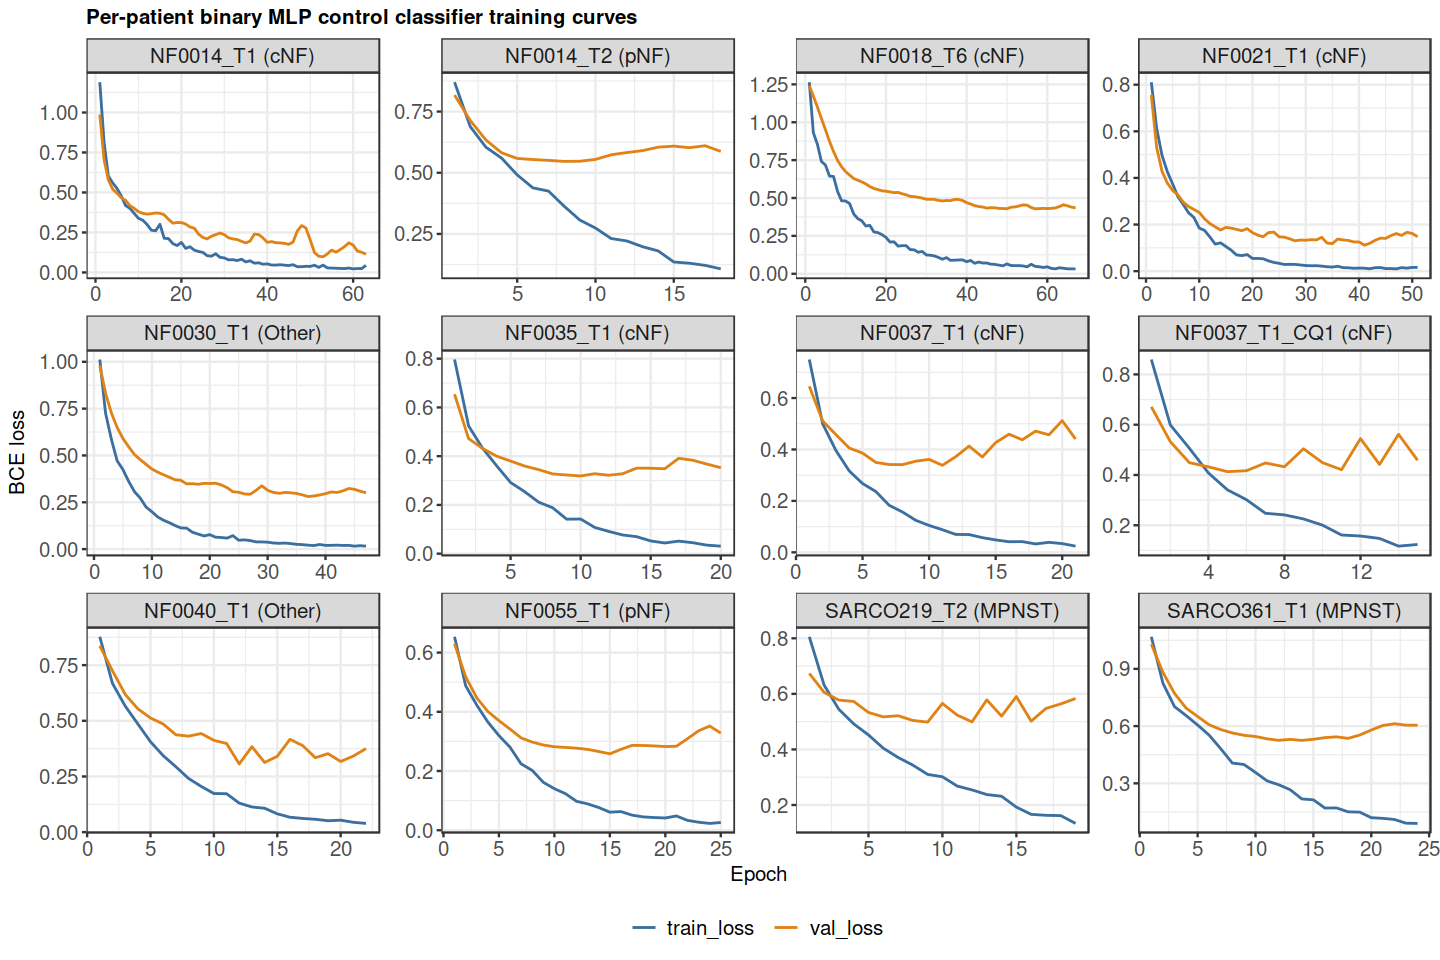

In [2]:
options(repr.plot.width = 12, repr.plot.height = 8)

training_curves_df <- read_parquet(
    file.path(results_dir, "binary_mlp_control_training_curves.parquet")
) %>%
    mutate(patient_label = label_patient(.data[[PATIENT_COL]])) %>%
    tidyr::pivot_longer(cols = c(train_loss, val_loss), names_to = "split", values_to = "loss")

training_curves_plot <- (
    ggplot(training_curves_df, aes(x = epoch, y = loss, colour = split))
    + geom_line(linewidth = 0.6)
    + facet_wrap(~patient_label, scales = "free")
    + scale_colour_manual(values = c(train_loss = "#3B6FA0", val_loss = "#E08214"), name = NULL)
    + labs(x = "Epoch", y = "BCE loss", title = "Per-patient binary MLP control classifier training curves")
    + theme_manuscript(base_size = 12)
    + theme(legend.position = "bottom")
)

ggsave(
    file.path(figures_dir, "binary_mlp_control_training_curves.png"),
    training_curves_plot, width = 12, height = 8, dpi = 600, bg = "white"
)
training_curves_plot

## 2. Precision-recall curves

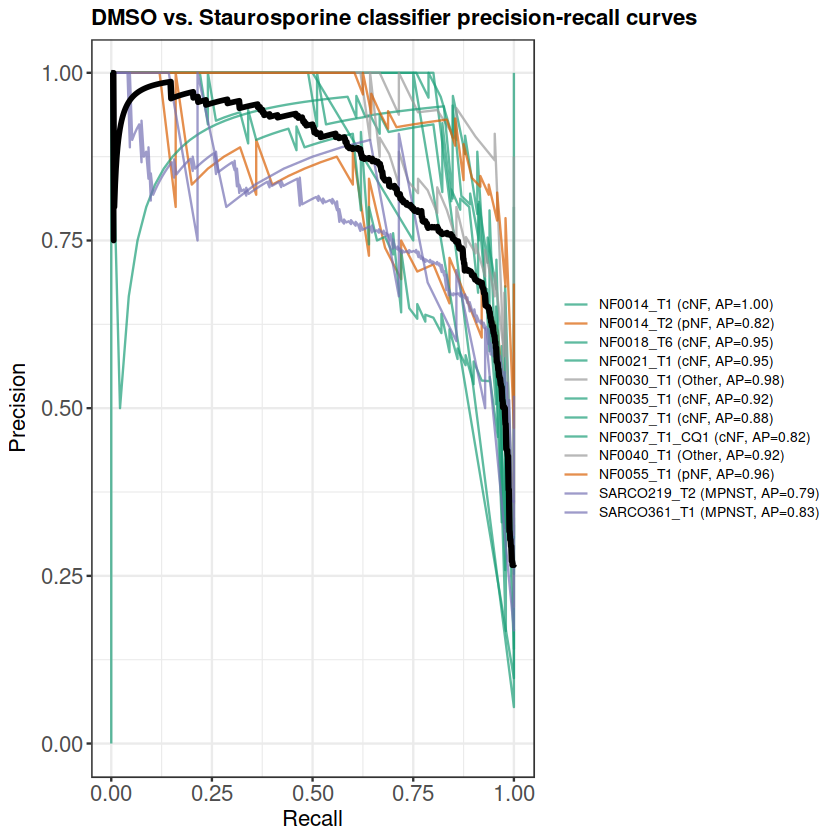

In [3]:
options(repr.plot.width = 7, repr.plot.height = 7)

pr_curve_df <- read_parquet(
    file.path(results_dir, "binary_mlp_control_pr_curve_points.parquet")
) %>%
    mutate(
        colour = series_colour(series),
        label = series_label(series, average_precision, "AP"),
        is_pooled = series == "pooled"
    )
pr_label_order <- pr_curve_df %>% distinct(series, label, is_pooled) %>% arrange(is_pooled, series)
pr_curve_df$label <- factor(pr_curve_df$label, levels = pr_label_order$label)
pr_colour_values <- setNames(
    pr_curve_df$colour[match(pr_label_order$label, pr_curve_df$label)], pr_label_order$label
)

pr_curves_plot <- (
    ggplot(pr_curve_df, aes(x = recall, y = precision, colour = label, group = label))
    + geom_line(data = filter(pr_curve_df, !is_pooled), linewidth = 0.5, alpha = 0.7)
    + geom_line(data = filter(pr_curve_df, is_pooled), linewidth = 1.2, colour = "black")
    + scale_colour_manual(values = pr_colour_values, name = NULL)
    + labs(
        x = "Recall", y = "Precision",
        title = "DMSO vs. Staurosporine classifier precision-recall curves"
    )
    + theme_manuscript(base_size = 13)
    + theme(legend.text = element_text(size = 8), legend.key.height = unit(4, "mm"))
)

ggsave(
    file.path(figures_dir, "binary_mlp_control_pr_curves.png"),
    pr_curves_plot, width = 7, height = 7, dpi = 600, bg = "white"
)
pr_curves_plot